# Mortgage Backed Securities Prepayment Prediction Using Machine Learning

## Objective
Predict whether a mortgage loan is likely to be prepaid using the **Freddie Mac 2024 sample dataset**.

Models compared:
- Logistic Regression
- RBF Support Vector Machine (SVM)
- Random Forest
- Feed-Forward Neural Network

### Methodology
- 60% training, 20% validation, 20% test
- Stratified splitting
- Class imbalance handled with `class_weight="balanced"` where applicable
- Classification thresholds tuned **only on validation data**
- Final model selected using **validation F1-score**
- Test set used only for final evaluation
- SVM uses `decision_function()` rather than slow probability calibration


## 1. Import Libraries

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42


## 2. Load the Freddie Mac 2024 Sample

In [2]:
from pathlib import Path

project_root = Path("..")
if not (project_root / "data" / "raw" / "sample_2024").exists():
    project_root = Path(".")

orig_path = project_root / "data" / "raw" / "sample_2024" / "sample_orig_2024.txt"
perf_path = project_root / "data" / "raw" / "sample_2024" / "sample_perf_2024.txt"

if not orig_path.exists() or not perf_path.exists():
    raise FileNotFoundError(
        "Could not find the Freddie Mac 2024 sample files. "
        "Run this notebook from the project root or notebooks folder."
    )

orig = pd.read_csv(orig_path, sep="|", header=None, low_memory=False)
perf = pd.read_csv(perf_path, sep="|", header=None, low_memory=False)

print("Origination data shape:", orig.shape)
print("Performance data shape:", perf.shape)


Origination data shape: (50000, 31)
Performance data shape: (952865, 35)


## 3. Assign Column Names

In [3]:
orig_cols = [
    "credit_score","first_payment_date","first_time_homebuyer_flag","maturity_date",
    "msa","mortgage_insurance_percentage","number_of_units","occupancy_status",
    "original_cltv","original_dti","original_upb","original_ltv",
    "original_interest_rate","channel","prepayment_penalty_mortgage_flag",
    "amortization_type","property_state","property_type","postal_code",
    "loan_sequence_number","loan_purpose","original_loan_term",
    "number_of_borrowers","seller_name","servicer_name","super_conforming_flag",
    "pre_relief_refinance_loan_sequence_number","special_eligibility_program",
    "relief_refinance_indicator","property_valuation_method",
    "interest_only_indicator"
]

perf_cols = [
    "loan_sequence_number","monthly_reporting_period","current_actual_upb",
    "current_loan_delinquency_status","loan_age","remaining_months_to_legal_maturity",
    "repurchase_flag","modification_flag","zero_balance_code","zero_balance_effective_date",
    "current_interest_rate","current_deferred_upb","due_date_of_last_paid_installment",
    "mi_recoveries","net_sale_proceeds","non_mi_recoveries","expenses","legal_costs",
    "maintenance_and_preservation_costs","taxes_and_insurance","miscellaneous_expenses",
    "actual_loss_calculation","modification_cost","step_modification_flag",
    "deferred_payment_plan","estimated_loan_to_value","zero_balance_removal_upb",
    "delinquent_accrued_interest","delinquency_due_to_disaster",
    "borrower_assistance_status_code","current_month_modification_cost",
    "current_month_deferral_amount","interest_bearing_upb",
    "principal_and_interest_payment","scheduled_principal_current"
]

orig.columns = orig_cols
perf.columns = perf_cols

print("Origination columns:", len(orig.columns))
print("Performance columns:", len(perf.columns))


Origination columns: 31
Performance columns: 35


## 4. Create the Prepayment Target

In [4]:
perf_check = perf.copy()
perf_check["zero_balance_code_num"] = pd.to_numeric(
    perf_check["zero_balance_code"], errors="coerce"
)
perf_check["prepaid_record"] = perf_check["zero_balance_code_num"].eq(1)

prepaid_loans = (
    perf_check.groupby("loan_sequence_number")["prepaid_record"]
    .max().astype(int)
)

orig["loan_sequence_number"] = orig["loan_sequence_number"].astype(str).str.strip()
prepaid_loans.index = prepaid_loans.index.astype(str).str.strip()

target = prepaid_loans.reset_index().rename(
    columns={"prepaid_record":"prepaid"}
)

ml_data = orig.merge(target, on="loan_sequence_number", how="inner")

print("ML dataset shape:", ml_data.shape)
print("\nTarget counts:")
print(ml_data["prepaid"].value_counts())
print("\nTarget percentage:")
print((ml_data["prepaid"].value_counts(normalize=True)*100).round(2))


ML dataset shape: (50000, 32)

Target counts:
prepaid
0    40823
1     9177
Name: count, dtype: int64

Target percentage:
prepaid
0    81.65
1    18.35
Name: proportion, dtype: float64


## 5. Select Model Features

In [5]:
categorical_cols = [
    "first_time_homebuyer_flag","occupancy_status","channel",
    "prepayment_penalty_mortgage_flag","amortization_type","property_state",
    "property_type","loan_purpose","seller_name","servicer_name",
    "special_eligibility_program","property_valuation_method",
    "relief_refinance_indicator","interest_only_indicator"
]

numerical_cols = [
    "credit_score","first_payment_date","maturity_date","msa",
    "mortgage_insurance_percentage","number_of_units","original_cltv",
    "original_dti","original_upb","original_ltv","original_interest_rate",
    "postal_code","original_loan_term","number_of_borrowers"
]

feature_cols = numerical_cols + categorical_cols
X = ml_data[feature_cols].copy()
y = ml_data["prepaid"].astype(int).copy()

print("Total input features:", len(feature_cols))
print("Numerical:", len(numerical_cols))
print("Categorical:", len(categorical_cols))


Total input features: 28
Numerical: 14
Categorical: 14


## 6. Train / Validation / Test Split

In [6]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp,
    random_state=RANDOM_STATE
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Training: (30000, 28)
Validation: (10000, 28)
Test: (10000, 28)


## 7. Preprocessing

In [7]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])


## 8. Evaluation and Threshold Helpers

In [8]:
def get_scores(model, X_data):
    classifier = model.named_steps["classifier"]

    if isinstance(classifier, SVC) and not classifier.probability:
        return model.decision_function(X_data)

    return model.predict_proba(X_data)[:, 1]


def find_best_threshold(y_true, scores):
    unique_scores = np.unique(scores)

    if len(unique_scores) > 500:
        thresholds = np.unique(
            np.quantile(unique_scores, np.linspace(0.01, 0.99, 499))
        )
    else:
        thresholds = unique_scores

    best_threshold = float(thresholds[0])
    best_f1 = -1.0

    for threshold in thresholds:
        pred = (scores >= threshold).astype(int)
        current_f1 = f1_score(y_true, pred, zero_division=0)

        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = float(threshold)

    return best_threshold, best_f1


def evaluate_model(y_true, pred, scores):
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1-Score": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, scores)
    }


## 9. Logistic Regression

In [9]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)
logistic_val_scores = get_scores(logistic_model, X_val)
logistic_threshold, logistic_val_f1 = find_best_threshold(
    y_val, logistic_val_scores
)

print("Logistic Regression trained.")
print("Validation threshold:", round(logistic_threshold, 4))
print("Validation F1:", round(logistic_val_f1, 4))


Logistic Regression trained.
Validation threshold: 0.5461
Validation F1: 0.4281


## 10. RBF Support Vector Machine

**Important:** `probability=False` is intentional. It avoids the very slow probability calibration that caused the previous notebook to take a very long time.

The SVM decision score is used for threshold tuning and ROC-AUC.


In [10]:
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        probability=False,
        random_state=RANDOM_STATE
    ))
])

svm_model.fit(X_train, y_train)
svm_val_scores = get_scores(svm_model, X_val)
svm_threshold, svm_val_f1 = find_best_threshold(
    y_val, svm_val_scores
)

print("RBF SVM trained.")
print("Validation threshold:", round(svm_threshold, 4))
print("Validation F1:", round(svm_val_f1, 4))


RBF SVM trained.
Validation threshold: 0.3167
Validation F1: 0.4304


## 11. Random Forest

In [11]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=18,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
rf_val_scores = get_scores(rf_model, X_val)
rf_threshold, rf_val_f1 = find_best_threshold(
    y_val, rf_val_scores
)

print("Random Forest trained.")
print("Validation threshold:", round(rf_threshold, 4))
print("Validation F1:", round(rf_val_f1, 4))


Random Forest trained.
Validation threshold: 0.4762
Validation F1: 0.4194


## 12. Feed-Forward Neural Network

In [12]:
nn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=100,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=RANDOM_STATE
    ))
])

nn_model.fit(X_train, y_train)
nn_val_scores = get_scores(nn_model, X_val)
nn_threshold, nn_val_f1 = find_best_threshold(
    y_val, nn_val_scores
)

print("Neural Network trained.")
print("Validation threshold:", round(nn_threshold, 4))
print("Validation F1:", round(nn_val_f1, 4))


Neural Network trained.
Validation threshold: 0.223
Validation F1: 0.4294


## 13. Select the Final Model Using Validation F1

The test set is **not** used here.

F1-score is the primary selection metric because the prepaid class is the minority class.


In [13]:
validation_results = pd.DataFrame([
    ["Logistic Regression", logistic_val_f1, logistic_threshold],
    ["RBF SVM", svm_val_f1, svm_threshold],
    ["Random Forest", rf_val_f1, rf_threshold],
    ["Neural Network", nn_val_f1, nn_threshold]
], columns=["Model", "Validation F1", "Threshold"])

validation_results = validation_results.sort_values(
    "Validation F1", ascending=False
).reset_index(drop=True)

display(validation_results.round(4))

models = {
    "Logistic Regression": logistic_model,
    "RBF SVM": svm_model,
    "Random Forest": rf_model,
    "Neural Network": nn_model
}

thresholds = dict(zip(validation_results["Model"], validation_results["Threshold"]))

best_model_name = validation_results.loc[0, "Model"]
final_model = models[best_model_name]
final_threshold = float(thresholds[best_model_name])

print("\nSelected final model:", best_model_name)
print("Selected threshold:", final_threshold)


,Model,Validation F1,Threshold
0,RBF SVM,0.4304,0.3167
1,Neural Network,0.4294,0.2230
2,Logistic Regression,0.4281,0.5461
3,Random Forest,0.4194,0.4762



Selected final model: RBF SVM
Selected threshold: 0.31669627124640987


## 14. Final Evaluation on the Unseen Test Set

In [14]:
final_test_scores = get_scores(final_model, X_test)
final_test_pred = (final_test_scores >= final_threshold).astype(int)

final_metrics = evaluate_model(
    y_test, final_test_pred, final_test_scores
)

final_metrics_df = pd.DataFrame([final_metrics], index=[best_model_name])
display(final_metrics_df.round(4))

print("Final threshold:", round(final_threshold, 4))


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
RBF SVM,0.7475,0.3722,0.5477,0.4432,0.7393


Final threshold: 0.3167


## 15. Test-Set Comparison

This table reports all models on the same unseen test set using thresholds selected from validation.

It is for reporting only; **the winner was already selected using validation F1**.


In [15]:
test_rows = []

for name, model in models.items():
    scores = get_scores(model, X_test)
    threshold = thresholds[name]
    pred = (scores >= threshold).astype(int)

    row = evaluate_model(y_test, pred, scores)
    row["Model"] = name
    row["Threshold"] = threshold
    test_rows.append(row)

test_results = pd.DataFrame(test_rows)[
    ["Model","Threshold","Accuracy","Precision","Recall","F1-Score","ROC-AUC"]
]

display(test_results.round(4))


,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.5461,0.7095,0.3389,0.6131,0.4365,0.7375
1,RBF SVM,0.3167,0.7475,0.3722,0.5477,0.4432,0.7393
2,Random Forest,0.4762,0.7529,0.3725,0.5063,0.4292,0.7345
3,Neural Network,0.2230,0.7327,0.3554,0.5613,0.4352,0.7349


## 16. Final Confusion Matrix

[[6470 1695]
 [ 830 1005]]


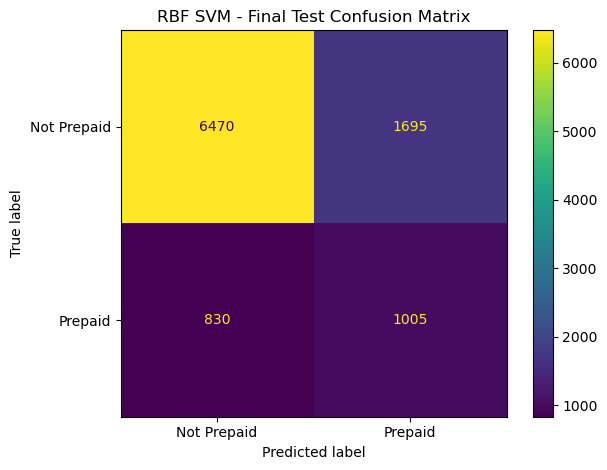

In [16]:
cm = confusion_matrix(y_test, final_test_pred)

print(cm)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_test_pred,
    display_labels=["Not Prepaid", "Prepaid"]
)
plt.title(f"{best_model_name} - Final Test Confusion Matrix")
plt.tight_layout()
plt.show()


## 17. Final ROC Curve

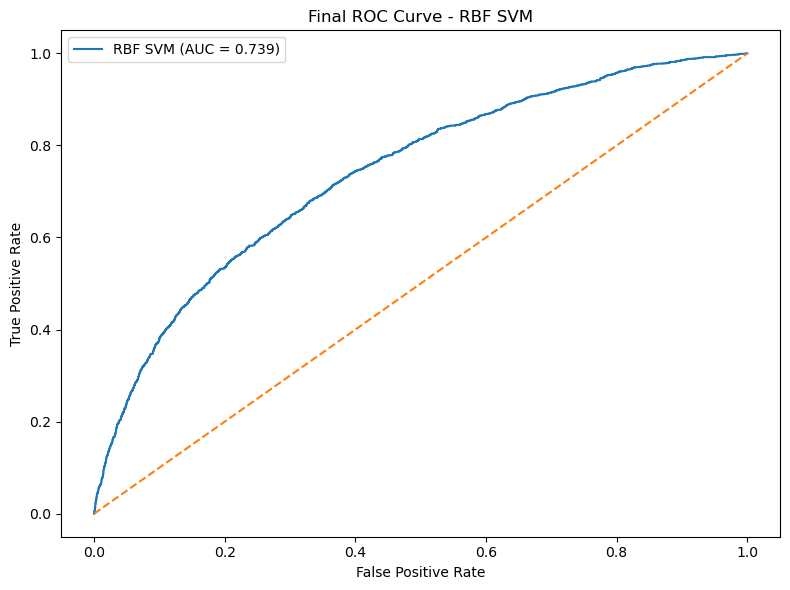

In [17]:
fpr, tpr, _ = roc_curve(y_test, final_test_scores)
auc_value = roc_auc_score(y_test, final_test_scores)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"{best_model_name} (AUC = {auc_value:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"Final ROC Curve - {best_model_name}")
plt.legend()
plt.tight_layout()
plt.show()


## 18. Validation F1 Comparison

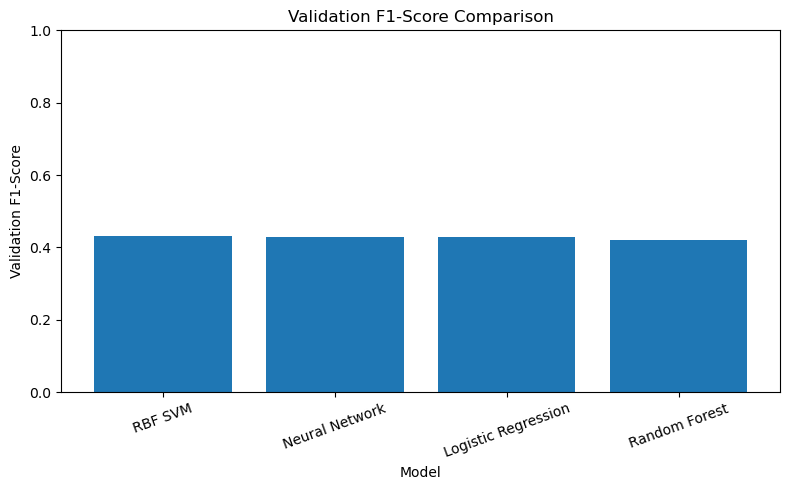

In [18]:
plt.figure(figsize=(8, 5))
plt.bar(validation_results["Model"], validation_results["Validation F1"])
plt.ylabel("Validation F1-Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.title("Validation F1-Score Comparison")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 19. Save the Final Model

In [19]:
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "mortgage_prepayment_final.pkl"
threshold_path = models_dir / "final_threshold.pkl"
metadata_path = models_dir / "final_model_metadata.pkl"

joblib.dump(final_model, model_path)
joblib.dump(final_threshold, threshold_path)

metadata = {
    "model_name": best_model_name,
    "threshold": final_threshold,
    "selection_metric": "Validation F1-Score",
    "dataset": "Freddie Mac 2024 sample",
    "random_state": RANDOM_STATE
}
joblib.dump(metadata, metadata_path)

print("Saved final model:", model_path)
print("Saved threshold:", threshold_path)
print("Saved metadata:", metadata_path)


Saved final model: ..\models\mortgage_prepayment_final.pkl
Saved threshold: ..\models\final_threshold.pkl
Saved metadata: ..\models\final_model_metadata.pkl


## 20. Verify the Saved Model

In [20]:
loaded_model = joblib.load(model_path)
loaded_threshold = joblib.load(threshold_path)
loaded_metadata = joblib.load(metadata_path)

loaded_scores = get_scores(loaded_model, X_test)
loaded_pred = (loaded_scores >= loaded_threshold).astype(int)
loaded_f1 = f1_score(y_test, loaded_pred, zero_division=0)

print("Loaded model:", loaded_metadata["model_name"])
print("Loaded threshold:", loaded_threshold)
print("Reloaded test F1:", round(loaded_f1, 4))
print("Original final test F1:", round(final_metrics["F1-Score"], 4))

assert loaded_metadata["model_name"] == best_model_name
assert np.isclose(loaded_threshold, final_threshold)
assert np.isclose(loaded_f1, final_metrics["F1-Score"])

print("\nModel verification successful.")


Loaded model: RBF SVM
Loaded threshold: 0.31669627124640987
Reloaded test F1: 0.4432
Original final test F1: 0.4432

Model verification successful.


# Conclusion

The project predicts mortgage prepayment using the Freddie Mac 2024 sample dataset.

Four machine-learning models are compared: Logistic Regression, RBF SVM, Random Forest, and a Feed-Forward Neural Network. Because the prepaid class is imbalanced, F1-score is used as the main model-selection metric.

Thresholds are optimized using the validation set. The final model is selected using validation F1-score, and the independent test set is used only for final evaluation.

The selected model and threshold are saved for deployment through the Streamlit application.

